# 🎯 **第10回：アプリケーションの作成（講義）**

## 内容
第10回目の講義では，Pythonだけでなくオブジェクト指向型プログラミング言語において重要なクラスの概念を学ぶ．クラスは関数以上に理解に手間取るプログラミングの仕組みであるが，使いこなすことができれば，非常に便利な仕組みである．また，クラスはこれまでの講義中にも実は登場している．詳細は後述するが，まず初めにクラスとは何か？関数との違いは？どのような場面で利用されるのか？について簡単に紹介したあと，データを管理する簡単なアプリケーションをクラスを利用して作成する．最終的に，画像を表示する機能や画像を保存する機能といった画像処理機能を作成したアプリケーションに追加する（発展課題を含む）．具体的には，以下の項目について理解し，クラスを使いこなせることが本講義の目標である．

- クラスの定義方法，クラスとインスタンス化の概念を理解する．
- インスタンス変数，インスタンスメソッドを定義できる．
- 【発展】他クラスから継承し，新たなクラスを作成できる．

## 🧩 **クラス**とは？

<div style="text-align: center;">
    <img src="./figs/class_image.png" width="50%" alt="インデントの画像">
</div>

**クラス（class）** とはデータの値や処理の振る舞いのルールを記述できる仕組みである．クラスや振る舞いのルールを理解するために，図に示すような設計図をイメージされたい．私たちは何かモノを作るとき，モノの情報や作り方を決めた設計図を予め作成し，その設計図をもとにモノを作成する．例えば，カメラの場合だと，製品名，大きさ，デザイン，レンズ，写真の保存の仕方など製造するためのあらゆる情報が設計図には記載されている．そして，設計図からカメラを製造し，完成品ができる．クラスはこの一連の手順に含まれるモノの設計書としてイメージすると良い．そして，後述するが，Pythonでは設計図をもとに作成された完成品を **インスタンス** または **オブジェクト** といい，インスタンスを作成することを **インスタンス化** という．

また，発展的な内容であるが，カメラの性能をアップデートしたり，デザインを変更した改良品の設計図を作成したい場合もある．Pythonでは，改良前の設計図をベースに新たな設計図を作成する **継承** という仕組みもサポートされている．クラスの簡単なイメージは以上であるが，厳密な定義や詳細な機能はゼロからはじめるプログラミングの内容を大幅に超えるため，本講義では，クラスがどのような場面で便利なのか？という視点から必要最低限の機能を紹介したい．

## 🧩 **クラスの利用場面**

次の機能を持つプログラムを作成する場面を想定されたい．あなたは動物園の管理者で種に基づいて名前，飼育場所，画像などをコンピュータで管理する必要がある．そして，あなたの働いている動物園には，ライオン（Lion），ゾウ（Elephant），キリン（Giraffe）が飼育されており，それぞれ，ガウス（Gauss），オイラー（Euler），ニュートン（Newton）と名前が付けられ，異なるケージで飼育されている．これまでの知識を利用して `{動物種}の{名前}は{飼育場所}で飼育されています．` と `print` してみる．

このような複数データを扱う場合，リストが便利であった．

In [64]:
species = ['Lion', 'Elephant', 'Giraffe']
names = ['Gauss', 'Euler', 'Newton']
locations = ['Cage A', 'Cage B', 'Cage C']

`print`文を使って煩雑なコードであるが以下のように出力できる．

In [34]:
for i in range(3):
    print(f'{species[i]}の{names[i]}は{locations[i]}にいます．')

LionのGaussはCage Aにいます．
ElephantのEulerはCage Bにいます．
GiraffeのNewtonはCage Cにいます．


出力することができた．では，ケージDで飼育されているアルパカのポアソンを追加する．

In [35]:
species = ['Lion', 'Elephant', 'Giraffe', 'Alpaca']
names = ['Gauss', 'Euler', 'Newton', 'Poisson']
locations = ['Cage A', 'Cage B', 'Cage C', 'Cage D']

for i in range(4):
    print(f'{species[i]}の{names[i]}は{locations[i]}にいます．')

LionのGaussはCage Aにいます．
ElephantのEulerはCage Bにいます．
GiraffeのNewtonはCage Cにいます．
AlpacaのPoissonはCage Dにいます．


出力することができた．（少量のデータであれば）複数個のデータをリストを用いて管理できることがわかった．

しかしながら，4頭しか飼育していない動物園は稀である．次のような場面を想像されたい．
- 飼育している動物が100頭以上いたらどうなるだろうか？
- 体温や体重など定期的に更新する必要があるデータを管理したいときはどうすればいいか？
- 繁殖に成功し，新たにライオンを追加したいときはどうすればいいだろうか？
- 動物の画像や説明文なども一緒に管理したり，画像を出力するためにはどうすればいいだろうか？

リストで管理しようと思うと，データが増えたり，新たな情報や機能を追加しようとしたとき，再度リストの定義を行い，プログラムを大きく書き換える必要がある．`range`関数や繰り返し処理の導入理由と同じように，大量のデータを持つ複数のリストの管理はデータの管理やコードの可読性の問題からプログラム作成者にとって非常に大変な作業となる．そこで便利なのがクラスという仕組みである．以降，発展内容を含むが上記の例をベースにクラスを説明する．

### 【発展】 `zip`文による複数データの処理
`zip`文は発展内容として位置付けられていたがこのような場面では便利な関数であり，`zip`文を使って`species`，`names`，`locations`を同時に繰り返すこともできる．詳細は第６回繰り返し処理の`zip`関数の使い方を参考されたい．

In [65]:
for n, s, l in zip(names, species, locations):
    print(f'{s}の{n}は{l}にいます．')

LionのGaussはCage Aにいます．
ElephantのEulerはCage Bにいます．
GiraffeのNewtonはCage Cにいます．


## 🧩 **クラスの作成**

<div style="text-align: center;">
    <img src="./figs/class.png" width="50%" alt="インデントの画像">
</div>

クラスは以下のように `class` を使うと定義することができる．以下はクラスの定義例である．`__init__` を実装することで，オブジェクトの初期状態を構築する

```python
class クラス名:
    def __init__(self):
        初期化処理
```

`class`に加えて`__init__`と`self`という新たな処理と名前が登場した．簡単に説明すると，`__init__`はクラスからデータを作成したときに一度だけ実行される初期化処理（**初期化メソッド**）である．また`self`はクラス自身を示す変数である．`self`はインスタンス変数と呼ばれるクラスに保存された変数にアクセスするために利用される変数である．詳細は後述する．

これ以外にも，クラスには複数の機能がサポートされており，書き方にはさまざまな流儀がある．まずはコピー&ペーストでいいので使い方に慣れてほしい．

上図に示すような動物を管理するための`Animal`クラスを以下のように定義する．

In [66]:
class Animal:
    def __init__(self):
        print('動物クラスを作成しました')

上記のセルはクラスが持つルール（ここでは初期化メソッドのみ）を定義した．ここではクラスがもつ処理を定義しただけなので利用するためにはクラスからデータの実体を作成する必要がある．これを **インスタンス化** といい，クラスから作成されたデータの実体を **インスタンス** または **オブジェクト** という．

In [67]:
a = Animal()

動物クラスを作成しました


上記のセルを実行して，`動物クラス`という`__init__`内の処理が実行されたことが確認できた．これがクラスのインスタンス化と`Animal`の**初期化処理**である．

### 【発展】 リストで学ぶインスタンス化
クラスとインスタンスはプログラミング初学者にとって非常にわかりにくい概念である．よくある説明例としては，前述のようにクラスは設計図，インスタンスは設計図をもとに作成されたモノであるというものである．もし，この説明例で理解ができなかったとしても，利用するだけなら容易であるため心配は不要である．第2回で学んだ **リスト** を思い出してほしい．リストの作成は既にできるはずである．

In [39]:
l = [1, 2, 3] # リストクラスからインスタンスの作成
print(l)

[1, 2, 3]


実は，上記の処理はリストの振る舞いを定義した設計図（クラス）からリストの実体 `l` を作成（インスタンス化）しているのである．ゼロから始めるプログラミングではクラスが利用できるだけも十分である．プログラムの内部の挙動や仕組みを理解する前に，コードを写径し，とりあえず実行してみることも大切である．

## 🧩 **インスタンス変数の作成**
続いて，`self`を理解するために，`Animal`クラスに種，名前，飼育場所を追加してみる．以下のように，`__init__`を書き換えることで実装できる．

```python
class クラス名:
    def __init__(self, variable):
        self.variable = variable
```

初期化処理を行う`__init__`関数の引数に変数（`variable`）が加えられ，関数内部で `self.variable = variable`の処理が追加された．
前者の引数は関数の回で学んだ．後者の処理はクラス自身を表す `self` に変数 `variable` を代入する処理である．言い換えると，クラス内部に変数 `variable` を保存する処理である．このクラスが持つ変数は **インスタンス変数** と呼ばれ，この処理によってデータを保持できるのである．

In [68]:
class Animal:
    def __init__(self, species):
        self.species = species

クラスからインスタンスを作成する．`__init__`に種を与える変数 `species` が加えられているのでインスタンス化のときに種の名前を与える．

In [69]:
a = Animal('Lion')

今回は，`__init__`で`print`をしていないので文字列が出力されていないことに注意されたい．インスタンス変数を出力するためには `インスタンス.インスタンス変数名`で変数にアクセスする．

In [70]:
a.species

'Lion'

続いて，名前と飼育場所も追加したクラスを作成する．

In [71]:
class Animal:
    def __init__(self, species, name, location):
        self.species = species
        self.name = name
        self.location = location

In [72]:
a = Animal('Lion', 'Gauss', 'Cage A')

print(a.species, a.name, a.location)
print(f'{a.species}の{a.name}は{a.location}にいます．')

Lion Gauss Cage A
LionのGaussはCage Aにいます．


また，他の動物のインスタンスも作成してみる．

In [73]:
a = Animal('Lion', 'Gauss', 'Cage A')
b = Animal('Elephant', 'Euler', 'Cage B')
c = Animal('Giraffe', 'Newton', 'Cage C')

異なるインスタンス変数が定義されていることが以下のセルからわかる．

In [46]:
print(f'{a.species}の{a.name}は{a.location}にいます．')
print(f'{b.species}の{b.name}は{b.location}にいます．')
print(f'{c.species}の{c.name}は{c.location}にいます．')

LionのGaussはCage Aにいます．
ElephantのEulerはCage Bにいます．
GiraffeのNewtonはCage Cにいます．


> <span style="font-size: 150%;">🧐</span>  
>
> **注意**
> * インスタンス変数は実行の手順からわかるように，**インスタンス化** されて初めてクラスに保存される変数である．
> * また `__init__` 内部で `variable` と `self.variable` はそれぞれ引数によって与えられた変数，インスタンスが持つ変数であることに注意されたい．これらの変数は意味が異なるのである．

## 🧩 **インスタンスメソッドの定義**
前述のセルでは作成した3つのインスタンスに対して `print` 文を呼び出した．データの管理はリストから容易になったが，処理は不便なままである．そこで，クラスが持つ機能を新たに追加する．このクラスが持つ機能は **インスタンスメソッド** または **インスタンス関数** と呼ばれ，以下のように定義できる．

```python
class クラス名:
    def __init__(self, variable):
        self.variable = variable

    def メソッド名(self, 引数):
        処理
```

`__init__`と同じ深さのインデントで新たなメソッド（処理）を定義している．これがインスタンスメソッドである．メソッドの第一引数は `self` を指定する．以下が，前述の `print` をインスタンスメソッドとして定義した `Animal` クラスである．

In [47]:
class Animal:
    def __init__(self, species, name, location):
        self.species = species
        self.name = name
        self.location = location

    def print_data(self):
        print(f'{self.species}の{self.name}は{self.location}にいます．')

初期化メソッド（`__init__`）で `self.species = species` でクラスが持つインスタンス変数を作成したが，このとき，上記のインスタンスメソッド内で `self.species` でインスタンス変数にアクセスしていることに着目されたい．後述するが，`print_data` で引数として `species` を与えることなく，このような処理が設計できることがポイントであり，第8回で学んだ関数との大きな違いである．

インスタンス化をする．

In [48]:
a = Animal('Lion', 'Gauss', 'Cage A')
b = Animal('Elephant', 'Euler', 'Cage B')
c = Animal('Giraffe', 'Newton', 'Cage C')

インスタンスメソッドは `インスタンス名.インスタンスメソッド名(引数)`で呼び出すことができる．

In [49]:
a.print_data()
b.print_data()
c.print_data()

LionのGaussはCage Aにいます．
ElephantのEulerはCage Bにいます．
GiraffeのNewtonはCage Cにいます．


もちろんインスタンス関数は第8回で学んだ関数のように`return`もできる．動物の情報をリストとして`return`する．

In [50]:
class Animal:
    def __init__(self, species, name, location):
        self.species = species
        self.name = name
        self.location = location

    def print_data(self):
        print(f'{self.species}の{self.name}は{self.location}にいます．')

    def get_data(self):
        animal_data = [self.species, self.name, self.location]
        return animal_data

リスト型のデータが`return`される．`return`されたデータを出力する．

In [51]:
a = Animal('Lion', 'Gauss', 'Cage A')
animal_data = a.get_data()
print(animal_data)

['Lion', 'Gauss', 'Cage A']


以上より，クラスにデータだけでなく機能（関数）を追加することができた．ここまででもリストと比較して便利にデータを管理できる．

> **ヒント**
> * 上記の`return`は第8回関数で複数の戻り値を利用せずに単一のリストで`return`している．タプルで複数の戻り値として実装することもできる．

### 【発展】 インスタンスメソッドをクラス内で呼び出す
インスタンスメソッドもまたインスタンス変数と同じようにクラス内で呼び出すことができる．`self.インスタンスメソッド名(引数)`で呼び出すことができる．以下のコードを参考にされたい．

In [52]:
class Animal:
    def __init__(self, species, name, location):
        self.species = species
        self.name = name
        self.location = location

    def print_data(self):
        print(f'{self.species}の{self.name}は{self.location}にいます．')

    def get_data(self):
        animal_data = [self.species, self.name, self.location]
        return animal_data

    def check_data(self):
        animal_data = self.get_data()
        print(animal_data)

上記の`Animal`クラスにはインスタンスメソッド`get_data`をインスタンスメソッド内で呼び出す`check_data`が追加で含まれている．`get_data`をインスタンスメソッド内で呼び出せることを確認するために，インスタンス化して，`check_data`メソッドを呼び出す．

In [53]:
a = Animal('Lion', 'Gauss', 'Cage A')
a.check_data()

['Lion', 'Gauss', 'Cage A']


`get_data`が呼び出されて，前述の例と同様の結果が得られたことがわかる．

### 【発展】 リストで学ぶインスタンスメソッド
発展内容であったが既に学んだ **リスト** の実態はリストの挙動がまとめられたクラスからインスタンス化されたデータであると説明した．リストは以下で定義できた．

In [54]:
l = [1, 2, 3] # リストクラスからインスタンスの作成
print(l)

[1, 2, 3]


ここで，再度，第2回の [リストの演算](https://colab.research.google.com/github/parqueprog/zero.prog/blob/main/docs/02/variables_and_data_types.ipynb) にある要素の追加・削除・挿入の説明を読み返してほしい．例えば，要素を追加したいときは，`リスト.append(追加する値)`と呼び出すとあった．

In [55]:
l.append(100)
print(l)

[1, 2, 3, 100]


実は，この`append`はインスタンスメソッドなのである．本講義では，クラス・インスタンス変数・インスタンスメソッドなど聞きなれない用語が多数現れるが，各データ型が持つ機能を調べさえすればプログラミングは容易にできるのである．言い換えると，**クラスの概念をある程度理解できれば，リストの機能を拡張したり，データ型自体を定義するといったことができるようになる**．

### 【発展】 関数とインスタンスメソッドの違い
ここまでのインスタンスメソッドの定義方法と利用場面を理解できた受講者はおそらく「関数とインスタンスメソッドの違いってなんだろう？」と疑問に思うだろう．厳密な違いを理解するためには，**オブジェクト指向プログラミング** そのものの説明が必要であり，ゼロからはじめるプログラミングの内容を大きく超えてしまうのでここでは以下のサンプルコードからこの違いを説明したい．

第8回の講義で学んだように関数は与えた入力に対してなんらかの処理をして出力する変換装置のイメージであった．上記の例と同様に， `{動物種}の{名前}は{飼育場所}で飼育されています．` と `print` する関数を考える．

In [56]:
def print_data(species, name, location):
    print(f'{species}の{name}は{location}で飼育されています．')


In [57]:
print_data('Lion', 'Gauss', 'Cage A')

LionのGaussはCage Aで飼育されています．


📌 **関数による管理の限界**
* 関数だけでもデータの出力（`print_data` など）は可能ですが、使うたびに**毎回引数を渡す必要がある**ため、管理するデータが膨大になったり複雑化すると不便になる。

💡 **クラス（インスタンスメソッド）を使うメリット**
* クラスの中に処理（メソッド）をまとめておけば、大量のデータを効率よく管理したり、データの構造を自由にカスタマイズしやすくなる。

In [58]:
a = Animal('Lion', 'Gauss', 'Cage A')
a.print_data()

LionのGaussはCage Aにいます．


この関数も同様の出力を得られるが，以下の2点が関数と異なる．

1. インスタンス変数を呼び出すことができる．
2. クラスに紐付けられている．

1点目は両者の引数を見てもわかるだろうが，インスタンスメソッドはメソッド内で引数に与えることなくインスタンス変数を参照できる．そのため，呼び出すたびに引数を指定する必要がなく，インスタンス変数に関係した機能を定義することができる．これと関連するが，インスタンスメソッドはクラスに備わっている関数であるため，類似した機能を持つクラスを定義するときや，複数のデータをクラスで管理するときに便利な仕組みとなる．詳細はリストによるクラスの管理やクラスの継承で後述する．クラスにおけるインスタンスメソッドは，関数の仕組みを **インスタンス変数** で拡張した仕組みとも言える．

また前述のリストで学ぶインスタンスメソッドを読むと，リストの要素を定義するインスタンス化の処理が必要であること，リストに新たな要素を追加する処理は関数よりもインスタンスメソッドとして定義されている方が便利であることがイメージできる．

##### 📌 **まとめ：クラスのまとめと簡単な例**

##### 1. **クラス（Class）**

* クラスは変数や処理（関数）をまとめた設計図のような機能である．
* このとき変数はインスタンス変数，処理はインスタンスメソッドと呼ばれる．
* クラスからデータの実態を作成するためにインスタンス化という手順が必要である．
* インスタンス化をしたとき初期化メソッドである `__init__`が呼び出される．
* クラス自身は `self` から参照できる．


##### 2. **クラスの作成（Class Definition）**
* `class` を使うと定義することができる．
* `__init__` によるオブジェクトの初期化．
    ```python
    class Animal:
        def __init__(self):
            print("動物クラスを作成しました")

    a = Animal()  # インスタンス化に伴う初期化処理の実行
    ```

##### 3. **インスタンス変数の作成（Instance Variables）**
* クラス内部に変数に保存する処理のことで，クラスが持つ変数は**インスタンス変数**と呼ばれる．
* `インスタンス.インスタンス変数名` で変数にアクセスする．
    ```python
    class Animal:
        def __init__(self, species, name):
            self.species = species  # インスタンス変数に代入
            self.name = name        # インスタンス変数に代入

    a = Animal("Lion", "Gauss")
    print(a.species)  # 属性値の参照 (出力: Lion)
    ```

##### 4. **インスタンスメソッドの定義（Instance Methods）**
* クラスが持つ機能のこと，**インスタンスメソッド**または**インスタンス関数**と呼ばれる．
* メソッドの**第一引数**は `self` を指定する．
    ```python
    class Animal:
        def __init__(self, species, name):
            self.species = species
            self.name = name

        def print_data(self):
            print(f"{self.species}の{self.name}")

    a = Animal("Lion", "Gauss")
    a.print_data()  # メソッドの実行 (出力: LionのGauss)
    ```

##### 5. **インスタンスメソッドをクラス内で呼び出す（Internal Method Invocation）**
* **インスタンスメソッド**もまた**インスタンス変数**と同じようにクラス内で呼び出すことができる．
* `self.インスタンスメソッド名(引数)` で**呼び出す**ことができる．
    ```python
    class Animal:
        def __init__(self, species, name):
            self.species = species
            self.name = name

        def get_name(self):
            return self.name

        def check_data(self):
            n = self.get_name()  # 内部メソッドの呼び出し
            print(f"名前は {n} です")

    a = Animal("Lion", "Gauss")
    a.check_data()  # 出力: 名前は Gauss です
    ```


## 画像表示機能の追加

作成した `Animal` クラスに画像表示機能を追加する．

まずは表示する画像をダウンロードする．Google ColabではLinuxのコマンドが利用できるので以下のセルを実行すると `data` フォルダの中に画像ファイルがダウンロードされる．また，以下のセルは講義資料上では，`mkdir: data: File exists`や`zsh:1: command not found: wget`とエラーが表示されているが，Google Colab上で実行すると正しく実行される．

In [82]:
!mkdir data
!wget -P data https://www.cs.hiroshima-u.ac.jp/zeropro/2023/11/data/elephant.jpg
!wget -P data https://www.cs.hiroshima-u.ac.jp/zeropro/2023/11/data/giraffe.jpg
!wget -P data https://www.cs.hiroshima-u.ac.jp/zeropro/2023/11/data/lion.jpg

mkdir: cannot create directory ‘data’: File exists


--2026-11-10 14:12:31--  https://www.cs.hiroshima-u.ac.jp/zeropro/2023/11/data/elephant.jpg
Resolving www.cs.hiroshima-u.ac.jp (www.cs.hiroshima-u.ac.jp)... 133.41.33.234
Connecting to www.cs.hiroshima-u.ac.jp (www.cs.hiroshima-u.ac.jp)|133.41.33.234|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 576479 (563K) [image/jpeg]
Saving to: ‘data/elephant.jpg’

elephant.jpg        100%[===================>] 562.97K  --.-KB/s    in 0.06s   

2026-11-10 14:12:31 (8.61 MB/s) - ‘data/elephant.jpg’ saved [576479/576479]

--2026-11-10 14:12:31--  https://www.cs.hiroshima-u.ac.jp/zeropro/2023/11/data/giraffe.jpg
Resolving www.cs.hiroshima-u.ac.jp (www.cs.hiroshima-u.ac.jp)... 133.41.33.234
Connecting to www.cs.hiroshima-u.ac.jp (www.cs.hiroshima-u.ac.jp)|133.41.33.234|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 587635 (574K) [image/jpeg]
Saving to: ‘data/giraffe.jpg’

giraffe.jpg         100%[===================>] 573.86K  --.-KB/s    in 0.07s


Linuxコマンドを覚えるとファイルやフォルダの操作などをCharacter-based User Interface（CUI）で行うことができる．発展的な内容なので上記のセルは実行するだけでいいが，セル内では，`!mkdir data`でGoogle Colab内に`data`という名前がついたフォルダを作成し，以降の`!wget -P data {URL}`で`URL`にある画像ファイルを先ほど作成した`data`フォルダにダウンロードするという操作をしている．

ダウンロードされたファイルは下の画像のフォルダアイコンをクリックすると確認できる．

<div style="text-align: center;">
    <img src="./figs/11_wget.png" width="75%" alt="インデントの画像">
</div>


```{caution}
上記のセルは一度だけセルを実行すれば良い．複数回実行すると `elephant 2.jpg`と複数の画像が保存される（複数枚画像があっても問題はありません）．
```

続いて，Pythonで画像を表示する機能を追加する．画像を管理・読み込み・表示するために `os`，`PIL`，`Matplotlib`というライブラリを利用する．ライブラリは便利な関数やクラスをまとめたものであり，例えば，`PIL`は画像を読み込んだり，編集したり，保存したりするための関数やクラスが提供されている．ライブラリにまとめられている関数やクラスは **モジュール** として扱われ，後述するセルのように簡単に利用することができる．ライブラリ，モジュール，`import`に関する説明は次回の講義で紹介するので，ここでは，これらのライブラリを使って画像を読み込み，表示するサンプルコードをコピー&ペーストでいいので動かしてほしい．

In [76]:
# 必要なライブラリのインポート
import os # 画像を保存するためのライブラリ
from PIL import Image # 画像を読み込むためのライブラリ
import matplotlib.pyplot as plt # 画像を出力するためのライブラリ
%matplotlib inline

これまでに作成した`Animal`クラスをコピー&ペーストして画像を表示するためのインスタンスメソッド `plot_image` を追加した`AnimalImage`クラスを定義する．

`plot_image`内の処理は以下である．コメントも参考に確認してほしい．
1. 画像の保存されたパスをインスタンス変数として管理
2. `PIL`という画像関連のライブラリを用いて画像を保存したパスから読み込む
3. `matplotlib` を利用して画像を表示するための準備をする
4. 画像のタイトルを設定
5. 画像を表示

```{admonition} パスについて
パスというのは画像のファイルが保存されている場所を示す．ここでは，`data/lion.jpg`としてパスを引数に与えているが，与えたパスを読み解くと，実行するプログラム（このJupyter Notebook）がある場所を起点に`data`フォルダ内の`lion.jpg`という画像を示している．
```

In [77]:
class AnimalImage:
    def __init__(self, species, name, location, img_path):
        self.species = species
        self.name = name
        self.location = location
        self.img_path = img_path # 1. 画像の保存されたパスをインスタンス変数として管理

    def print_data(self):
        print(f'{self.species}の{self.name}は{self.location}にいます．')

    def get_data(self):
        animal_data = [self.species, self.name, self.location]
        return animal_data

    # 画像を表示するためのインスタンスメソッド
    def plot_image(self):
        img = Image.open(self.img_path) # 2. `PIL`という画像関連のライブラリを用いて画像を保存したパスから読み込む
        plt.figure() # 3. `matplotlib` を利用して画像を表示するための準備をする
        plt.title(self.name) # 4. 画像のタイトルを設定
        plt.imshow(img) # 5. 画像を表示

定義した `AnimalImage` クラスをインスタンス化

In [78]:
a = AnimalImage('Lion', 'Gauss', 'Cage A', 'data/lion.jpg')

画像を表示する `plot_image` を呼び出す．

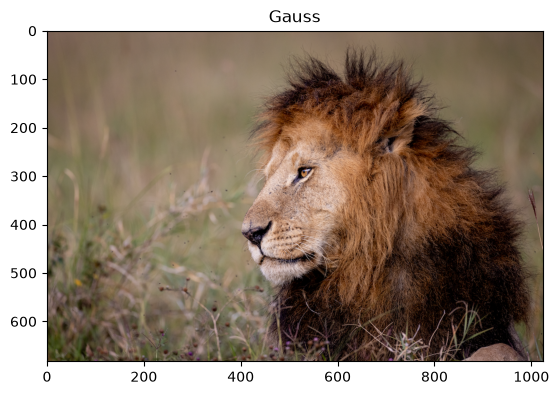

In [83]:
a.plot_image()

画像を表示することができた．しかしながら，機能や変数を追加する度に，クラスをコピー&ペーストして再定義するのは大変である．そこで，次は，**継承** という機能を使って`Animal`クラスの情報を引き継いで同様の`AnimalImage`クラスを実装することを試みる．

> **ヒント**
> * 本講義では **アプリケーションの作成** ということであったが，クラスの説明のボリュームが想定以上の量となってしまったため，画像を表示する機能のみをクラスを用いて作成した．
> * スマートフォンで普段利用しているアプリケーションとは程遠いプログラムとなってしまったが，本講義の演習に画像の大きさを変更し，保存する機能を追加する発展演習を作成したのでぜひ挑戦してほしい．
> * また，クリックなど視覚的かつ対話的に操作が行える **グラフィカルユーザインターフェース**(Graphical User Interface)の機能もPythonでは提供されている．
> * Google ColabやJupyter Notebook上でGUIアプリケーションを作成したい場合は，`ipywidgets`というライブラリを利用すると良い．[公式ページ](https://ipywidgets.readthedocs.io/en/latest/index.html)を参考に挑戦してみてほしい．

## 【発展】 リストによるクラスの管理
前述までのクラスの利用方法では，ある動物に対して新たな関数やデータを追加することは便利であるが，複数の動物を管理しようとしたとき，頭数分のインスタンスメソッドの呼び出しが必要となる．発展的なテクニックであるが，インスタンスをリストで管理するとループを使って便利に管理できる．

In [ ]:
zoo = [
    Animal('Lion', 'Gauss', 'Cage A'),
    Animal('Elephant', 'Euler', 'Cage B'),
    Animal('Giraffe', 'Newton', 'Cage C')]

for animal in zoo:
    animal.print_data()

このように管理すると新たな動物を加えるときも便利である．

In [ ]:
zoo = [
    Animal('Lion', 'Gauss', 'Cage A'),
    Animal('Elephant', 'Euler', 'Cage B'),
    Animal('Elephant', 'Maclaurin', 'Cage B'),
    Animal('Giraffe', 'Newton', 'Cage C'),
    Animal('Alpaca', 'Poisson', 'Cage D')]


for animal in zoo:
    animal.print_data()

また，`append` を使って`zoo`のリストを作成することも出来る．

In [ ]:
zoo = []

zoo.append(Animal('Lion', 'Gauss', 'Cage A'))
zoo.append(Animal('Elephant', 'Euler', 'Cage B'))
zoo.append(Animal('Giraffe', 'Newton', 'Cage C'))

for animal in zoo:
    animal.print_data()

また，`vars()` 関数や `__dict__` 属性を使用することで，オブジェクトが持つインスタンス変数と値のペアを辞書として取得することができる．

In [ ]:
vars(zoo[0])


In [ ]:
zoo[0].__dict__

## 【発展】 クラスの**継承**

<div style="text-align: center;">
    <img src="./figs/inheritance.png" width="50%" alt="インデントの画像">
</div>

これまでは新たな変数や機能を追加しようとしたとき，`Animal`クラスの再定義が必要であった．Pythonを含むオブジェクト指向型言語には，クラスの機能を別のクラスで再利用する **継承** という仕組みが提供されている．ここでは，継承を利用して，`Animal`クラスを再定義することなく，動物の画像を管理する変数や機能を追加する方法について説明する．

継承の方法は以下である．`class クラス名:`に継承するクラス名を与えると継承するクラスのインスタンスメソッドが利用できる．`super().__init__()`は継承するクラスの`__init__`関数を呼び出している．

```python
class クラス名(継承するクラス名):
    def __init__(self, variable, new_variable):
        self.new_variable = new_variable
        super().__init__(variable)

    def 新たに追加するメソッド名(self, 引数):
        処理
```

継承元のインスタンス変数を利用しない場合は `super()`を呼び出す必要はないことに注意されたい（インスタンスメソッドのみを利用したい場合など）．

実際に，画像も管理する `AnimalImage`クラスを`Animal`クラスから継承して作成する．

In [ ]:
class AnimalImage(Animal):
    def __init__(self, species, name, location, img_path):
        self.img_path = img_path # 1. 画像の保存されたパスをインスタンス変数として管理
        super().__init__(species, name, location)

    # 画像を表示するためのインスタンスメソッド
    def plot_image(self):
        img = Image.open(self.img_path) # 2. `PIL`という画像関連のライブラリを用いて画像を保存したパスから読み込む
        plt.figure() # 3. `matplotlib` を利用して画像を表示するための準備をする
        plt.title(self.name) # 4. 画像のタイトルを設定
        plt.imshow(img) # 5. 画像を表示

まず，継承の利点を理解するために，`Animal`クラスを再利用して作成した`AnimalImage`クラスには`Animal`クラスで定義されたインスタンス変数とインスタンスメソッドが利用できることを確認されたい．

In [ ]:
zoo = [
    AnimalImage('Lion', 'Gauss', 'Cage A', 'data/lion.jpg'),
    AnimalImage('Elephant', 'Euler', 'Cage B', 'data/elephant.jpg'),
    AnimalImage('Giraffe', 'Newton', 'Cage C', 'data/giraffe.jpg')]

for animal in zoo:
    animal.print_data()

このように再定義することなく継承元の機能を利用できることが継承の利点であり，追加したい機能だけをプログラミングすれば良い．
続いて，新たに追加した画像表示機能を呼び出す．

In [ ]:
for animal in zoo:
    animal.print_data()
    animal.plot_image()

継承元のメソッドと新たに追加したメソッドの両方を呼び出せることが確認できた．

今回紹介したライブラリ以外にも，`Numpy` や `Scikit-Learn` といったライブラリがある（次回以降の講義で紹介する）．ライブラリには関数やクラスとしてさまざまな機能が提供されているので興味があればチェックしてほしい．また，ライブラリを用いるとクラスを意識することなく便利な機能を利用することができるが，ReferenceやGitHubのソースコードを確認してみるとプログラミング力が身につくだろう．


> **重要**
> * 本講義は教養科目ということもあり，クラスの詳細な機能やオブジェクト指向型プログラミングに関する詳しい説明は省略している．
> * 本講義でPythonの基礎文法の内容は終了であるが，クラスだけでなく関数といったこれまで勉強した使い方以外にも，Pythonにはより綺麗で便利なプログラムを作成するための仕組みがいくつも提供されている．
> * ぜひ，本講義資料だけでなく，下記資料等を参考に自身で調べてみてほしい．

### さらに勉強したい人へ

ゼロからはじめるプログラミングの内容からさらに進んでコンピュータサイエンス，Pythonプログラミング，機械学習をもっと勉強したい人へ難しいけど勉強になる本をリストアップしました．

特に，プログラミングと機械学習の項は初学者向けではありませんが興味がある学生はぜひチャレンジしてみてください．

#### コンピュータの仕組み

- ロン・ホワイト 著, “コンピューター&テクノロジー解体新書”
- 矢沢久雄 著, “コンピュータはなぜ動くのか　知っておきたいハードウエア＆ソフトウエアの基礎知識”
- 矢沢久雄 著, “プログラムはなぜ動くのか 知っておきたいプログラミングの基礎知識”
- 坂井弘亮 著, “ハロー“Hello, World” OSと標準ライブラリのシゴトとしくみ”

#### Pythonプログラミング

- Bill Lubanovic 著, “入門 Python 3”
- Al Sweigart 著, “退屈なことはPythonにやらせよう ―ノンプログラマーにもできる自動化処理プログラミング”
- Luciano Ramalho 著, “Fluent Python ―Pythonicな思考とコーディング手法”
- Brett Slatkin 著, “Effective Python ―Pythonプログラムを改良する90項目”

#### Pythonによる機械学習

- Sebastian Raschka, Vahid Mirjalili 著, “Python機械学習プログラミング 達人データサイエンティストによる理論と実践”
- 八谷 大岳 著, “ゼロからつくるPython機械学習プログラミング入門”
- 斎藤 康毅 著, “ゼロから作るDeep Learning ―Pythonで学ぶディープラーニングの理論と実装”

上記以外にも勉強になる参考書やwebページがたくさんあります．
